# Customer segmentation
## 📊 Dataset

The project uses data from the **2019 Survey of Consumer Finances (SCF)** conducted by the **Federal Reserve Board**.

The SCF is one of the most comprehensive surveys of household finances in the United States, collecting information on:

* Household assets and liabilities
* Income and wealth
* Retirement accounts and pensions
* Debt and credit
* Demographic characteristics
* Financial behavior

The survey provides a nationally representative snapshot of the financial condition of U.S. families and is widely used by economists, researchers, policymakers, and financial institutions.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly_express as px


In [2]:
df = pd.read_csv("../data/raw/SCFP2019.csv")
df.head()

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,6119.779308,2,75,6,12,4,2,0,...,5,3,6,3,2,10,6,6,3,3
1,1,12,4712.374912,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
2,1,13,5145.224455,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
3,1,14,5297.663412,2,75,6,12,4,2,0,...,5,2,6,2,1,10,4,4,2,2
4,1,15,4761.812371,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28885 entries, 0 to 28884
Columns: 351 entries, YY1 to NINCQRTCAT
dtypes: float64(74), int64(277)
memory usage: 77.4 MB


In [4]:
# Subset data, houshold's whose TURNFEAR ==1
df_fear = df[df["TURNFEAR"]==1]
df_fear = df_fear.reset_index()
df_fear.info()

<class 'pandas.DataFrame'>
RangeIndex: 4623 entries, 0 to 4622
Columns: 352 entries, index to NINCQRTCAT
dtypes: float64(74), int64(278)
memory usage: 12.4 MB


/var/folders/f2/9hmkm0qs2rj3c57j0r334sbc0000gn/T/ipykernel_1577/3484933766.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fear = df_fear.reset_index()


TURNFEAR is a binary (0/1) variable that indicates whether a household:

1 = Was turned down for credit or feared being turned down for credit during the last 5 years.

0 = Was not turned down and did not fear being turned down during the last 5 years.

# EDA

## Project Objective

The objective of this project is to examine the characteristics of households with **`TURNFEAR = 1`**—those that were either denied credit or avoided applying for credit due to fear of rejection. By analyzing their demographic, financial, and socioeconomic attributes, we aim to gain a deeper understanding of the factors associated with credit access and the behavior of credit-constrained households.


In [5]:
# AGECL groups feature
df_fear["AGECL"].unique()

array([3, 5, 1, 2, 4, 6])

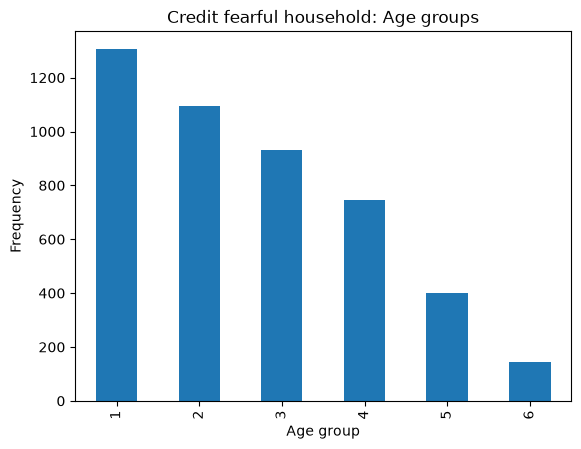

In [6]:
df_fear["AGECL"].value_counts().plot(
    kind="bar",
    xlabel="Age group",
    ylabel="Frequency",
    title="Credit fearful household: Age groups"
);

# From the dataset information the AGECL was encoded as follows 
| AGECL Value | Age Category |
| ----------- | ------------ |
| 1           | Under 35     |
| 2           | 35–44        |
| 3           | 45–54        |
| 4           | 55–64        |
| 5           | 65–74        |
| 6           | 75 or Older  |


In [7]:
# Extracting the age_cl column from AGECL
agecl_dict ={
    1: "under 35",
    2: "35-44",
    3: "45-54",
    4: "55-64",
    5: "65-74",
    6: "75 or Older"
}
age_cl = df_fear["AGECL"].replace(agecl_dict)

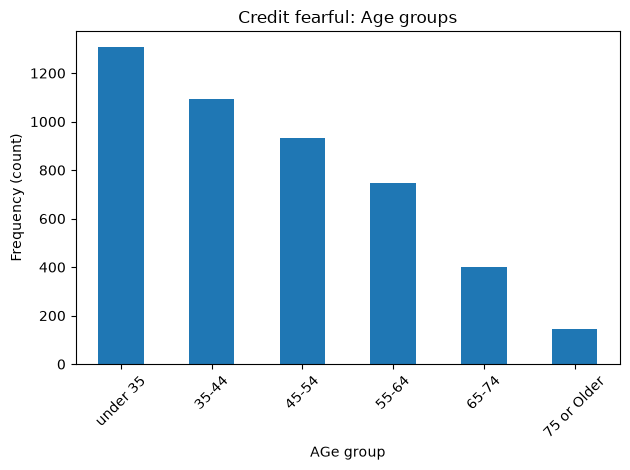

In [8]:
age_cl.value_counts().plot(
    kind="bar"
)
plt.xticks(rotation= 45)
plt.xlabel("AGe group")
plt.ylabel("Frequency (count)")
plt.title("Credit fearful: Age groups");
plt.tight_layout()
plt.savefig("../reports/figures/age_groups.png", dpi=150)

The Frequenct (count) of the `AGECL` feature shows that the `Under 35` , `35-44` age groups is the most prevalent category, suggesting that younger individuals make up the largest share of the sampled population.

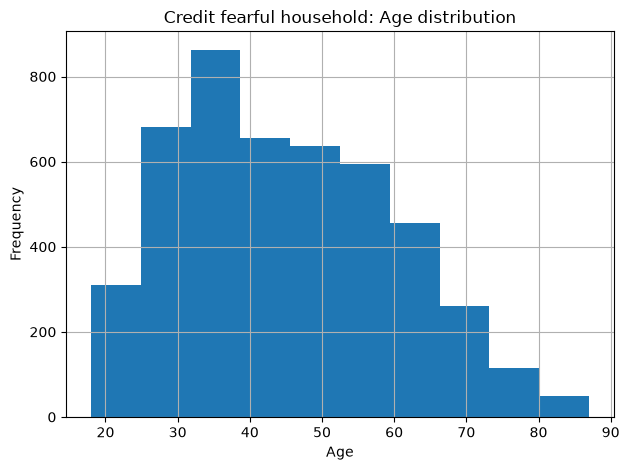

In [9]:
# Age distribution 
df_fear["AGE"].hist(bins=10)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Credit fearful household: Age distribution");
plt.tight_layout()
plt.savefig("../reports/figures/age_distribution.png", dpi=150)

The age distribution of the survey participants shows that the majority are between **35 and 60 years old**.

In [10]:
# Race 
df_fear["RACE"].unique()

array([1, 3, 2, 5])

**RACE Encoding (according to the data dictionary):**
- **1:** White/Non-Hispanic
- **2:** Black/African-American
- **3:** Hispanic
- **5:** Other

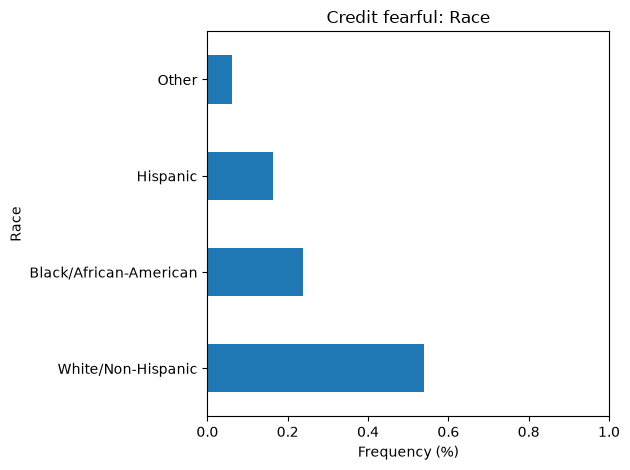

In [11]:
# Race encoding dictionary
race_dict = {
    1: "White/Non-Hispanic",
    2: "Black/African-American",
    3: "Hispanic",
    5: "Other",
}
race_fear = df_fear["RACE"].replace(race_dict)

race_fear.value_counts(normalize=True).plot(
    kind="barh"
)
plt.xlim((0,1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("Credit fearful: Race");
plt.tight_layout()
plt.savefig("../reports/figures/credit_fearful_race.png", dpi=150)

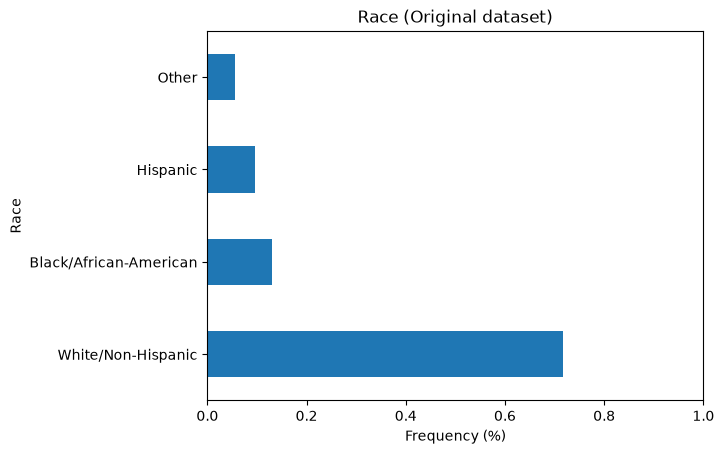

In [12]:
race_dict = {
    1: "White/Non-Hispanic",
    2: "Black/African-American",
    3: "Hispanic",
    5: "Other",
}
race = df["RACE"].replace(race_dict)

race.value_counts(normalize=True).plot(
    kind="barh"
)
plt.xlim((0,1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("Race (Original dataset)");

**Insight:** Comparing these two graphs highlights the importance of analyzing the complete dataset rather than a subset. While the distribution of Credit fearful households suggests that **White/Non-Hispanic** participants account for just over **50%** of the group, the distribution of the entire dataset shows that they actually represent **more than 70%** of all participants. This demonstrates that conclusions drawn from a subset may not accurately reflect the characteristics of the overall population.

In [13]:
# Race distribution in the original dataset
race.value_counts()

RACE
White/Non-Hispanic        20703
Black/African-American     3757
Hispanic                   2791
Other                      1634
Name: count, dtype: int64

In [14]:
# Race distribution in the subseted dataset [Fearful households]
race_fear.value_counts()

RACE
White/Non-Hispanic        2494
Black/African-American    1098
Hispanic                   750
Other                      281
Name: count, dtype: int64

In [15]:
race_df = pd.DataFrame({"df":race.value_counts(),"df_fear": race_fear.value_counts()})
race_df["race_precentage"] = race_df["df_fear"]/ race_df["df"]

In [16]:
race_df

,df,df_fear,race_precentage
RACE,,,
White/Non-Hispanic,20703,2494,0.120466
Black/African-American,3757,1098,0.292254
Hispanic,2791,750,0.268721
Other,1634,281,0.171971


<Axes: ylabel='RACE'>

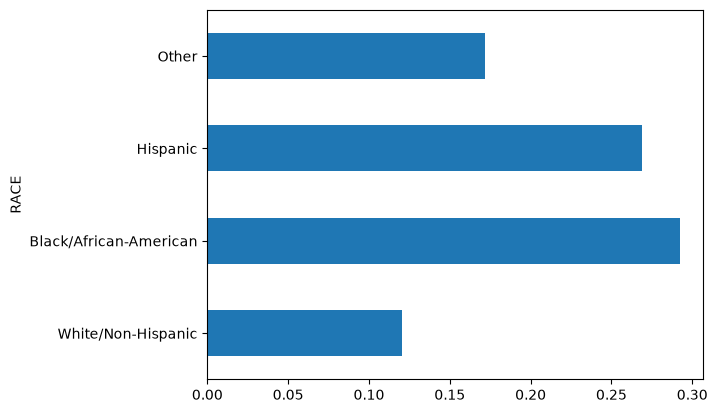

In [17]:
race_df["race_precentage"].plot(kind="barh")

### Insight

The graph shows that **Black/African American** participants represent the highest proportion of **credit-fearful households** relative to their representation in the overall dataset. Although they account for a smaller share of the original population, their percentage increases substantially within the credit-fearful subset.

> **Note:** This analysis is intended solely to understand the characteristics of the dataset and to compare the original population with the credit-fearful subset. The race and ethnicity variables are used only for descriptive statistical analysis to identify differences in representation and potential disparities within the data. These insights should not be used to stereotype, discriminate against, or make decisions about individuals based on their race or ethnicity. Instead, they help ensure that conclusions drawn from the dataset are accurate, transparent, and informed by the data.

## Income category feature



In [18]:
df_fear["INCCAT"].unique()

array([2, 1, 3, 6, 4, 5])

In [19]:
df_fear["INCCAT"].value_counts()

INCCAT
1    1332
2    1185
3    1058
4     613
6     226
5     209
Name: count, dtype: int64

### Income Percentile Category

The `income_percentile` variable is an **ordinal** measure of income rank, encoded as:

| Code | Percentile |
|------|------------|
| 1 | 0–20 |
| 2 | 21–39.9 |
| 3 | 40–59.9 |
| 4 | 60–79.9 |
| 5 | 80–89.9 |
| 6 | 90–100 |

In [20]:
incat_dict= {
    1:"0-20",
    2:"21-39.9",
    3:"40-59.9",
    4:"60-79.9",
    5:"80-89.9",
    6:"90-100"
}
df_inccat = (
    df["INCCAT"]
    .replace(incat_dict)
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)
    .rename("Frequency")
    .to_frame()
    .reset_index()

)

df_inccat

,TURNFEAR,INCCAT,Frequency
0,0,90-100,0.297296
1,0,60-79.9,0.174841
2,0,40-59.9,0.143146
3,0,0-20,0.140343
4,0,21-39.9,0.135933
5,0,80-89.9,0.108441
6,1,0-20,0.288125
7,1,21-39.9,0.256327
8,1,40-59.9,0.228856
9,1,60-79.9,0.132598


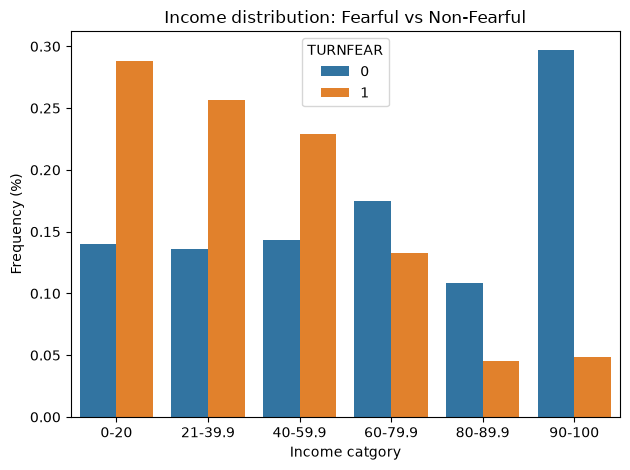

In [21]:
# Bar-chart (df_inccat)
sns.barplot(
    data=df_inccat,
    x="INCCAT",
    y="Frequency",
    hue="TURNFEAR",
    order=incat_dict.values()
);
plt.xlabel("Income catgory")
plt.ylabel("Frequency (%)")
plt.title("Income distribution: Fearful vs Non-Fearful")
plt.tight_layout()
plt.savefig("../reports/figures/Income_distribution.png", dpi=150);

### Income Category vs. Fearful households

Higher income levels are associated with lower fear of obtaining credit, indicating an inverse relationship between income and credit-related apprehension.

In [22]:
# Corelation between important features [ASSETS, HOUSES, INCOME, DEPT, EDUC]
corr = df[["ASSET", "HOUSES", "INCOME", "DEBT", "EDUC"]].corr()
corr.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.519827,0.622429,0.261250,0.116673
HOUSES,0.519827,1.000000,0.247852,0.266661,0.169300
INCOME,0.622429,0.247852,1.000000,0.114646,0.069400
DEBT,0.261250,0.266661,0.114646,1.000000,0.054179
EDUC,0.116673,0.169300,0.069400,0.054179,1.000000


In [23]:
# Education 
df_education = (
    df["EDUC"]
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)
    .rename("Frequency")
    .to_frame()
    .reset_index()
)
df_education.head()

,TURNFEAR,EDUC,Frequency
0,0,12,0.257481
1,0,8,0.192029
2,0,13,0.149823
3,0,9,0.129833
4,0,14,0.096117


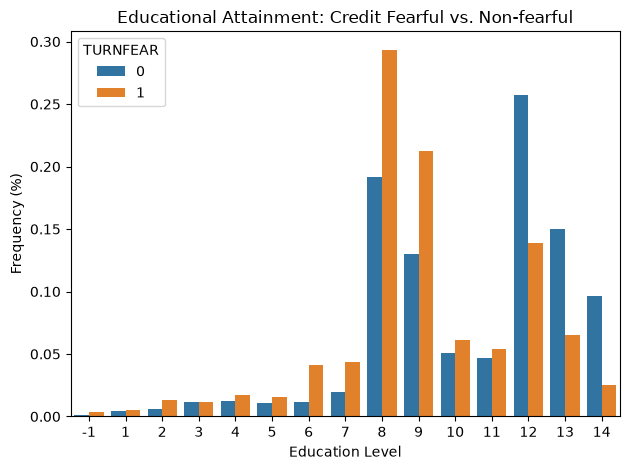

In [24]:
# Bar-chart for education
sns.barplot(
    data=df_education,
    x="EDUC",
    y="Frequency",
    hue="TURNFEAR"
)
plt.xlabel("Education Level")
plt.ylabel("Frequency (%)")
plt.title("Educational Attainment: Credit Fearful vs. Non-fearful");
plt.tight_layout()
plt.savefig("../reports/figures/education_distribution.png", dpi=150)

### Education Level vs. Fear of Obtaining Credit

Individuals with higher education levels are less likely to fear obtaining credit, possibly due to better employment opportunities and higher income.

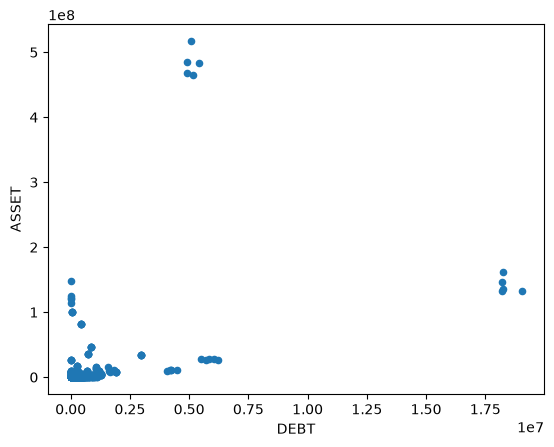

In [25]:
# DEBT vs ASSET - Fearful group
df_fear.plot.scatter(x="DEBT", y="ASSET");

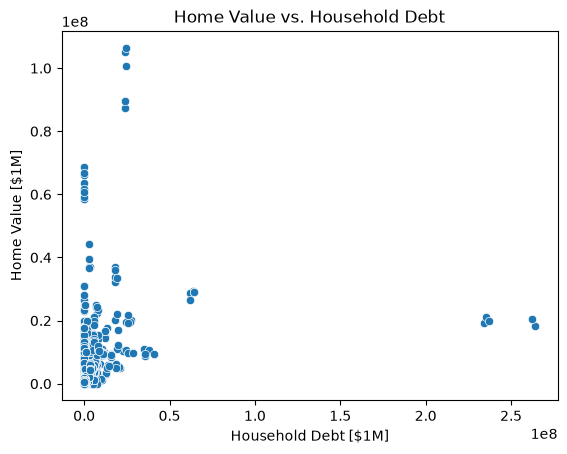

In [26]:
# Houses vs DEBT
sns.scatterplot(data=df, x="DEBT", y="HOUSES")
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Home Value vs. Household Debt");

# Clustering using two feature `[HOUSES, DEBT]`
## Credit fearful group

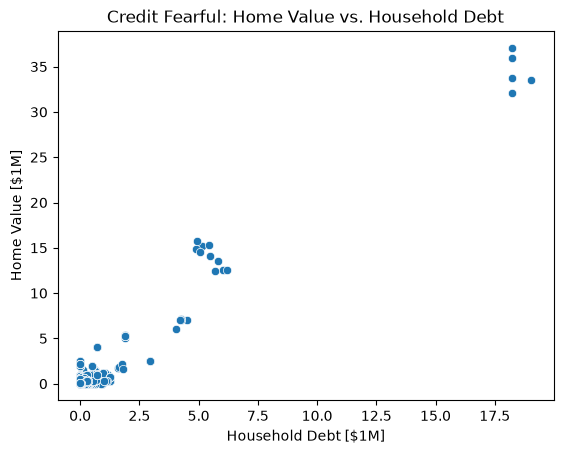

In [27]:
# Houses vs DEBT - Fearful group
sns.scatterplot(x=df_fear["DEBT"] / 1e6, y=df_fear["HOUSES"] / 1e6)
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

### Household Assets and Debt

The last two graphs suggest that overall household debt does not increase substantially with higher housing values. However, when focusing on the credit-fearful group, a strong positive relationship emerges between housing value and debt, indicating that these individuals may rely on their homes as collateral for borrowing. In contrast, no similarly strong relationship is observed between non-housing assets and debt, suggesting that ownership of other assets is not associated with higher debt levels.

In [28]:
# subset the data frame to income less that 500_000
# df_fear = df_fear[df_fear["INCOME"]< 500_000]

In [29]:
# Feature matrix 
X = df_fear[["HOUSES", "DEBT"]]


# Building K-means model


In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

model = KMeans(n_clusters=3, random_state=42)
model.fit(X)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[

In [31]:
labels = model.labels_

Text(0.5, 1.0, 'Credit feauful group: Home value vs Household debt')

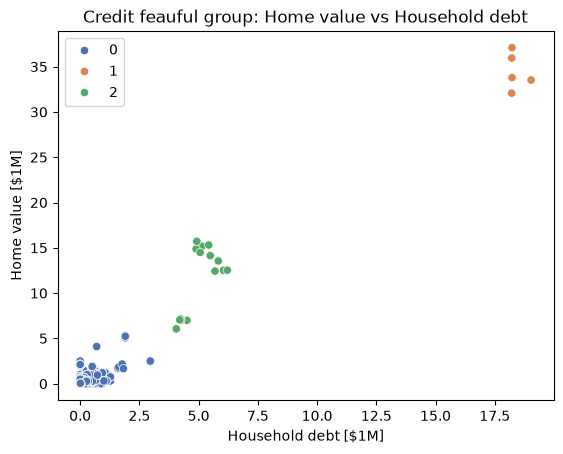

In [32]:
sns.scatterplot(x=df_fear["DEBT"] / 1e6, y=df_fear["HOUSES"] / 1e6, hue=labels, palette="deep")
plt.xlabel("Household debt [$1M]")
plt.ylabel("Home value [$1M]")
plt.title("Credit feauful group: Home value vs Household debt")

In [33]:
centroids = model.cluster_centers_
centroids

array([[  116150.29328699,    91017.57766674],
       [34484000.        , 18384100.        ],
       [11666666.66666667,  5065800.        ]])

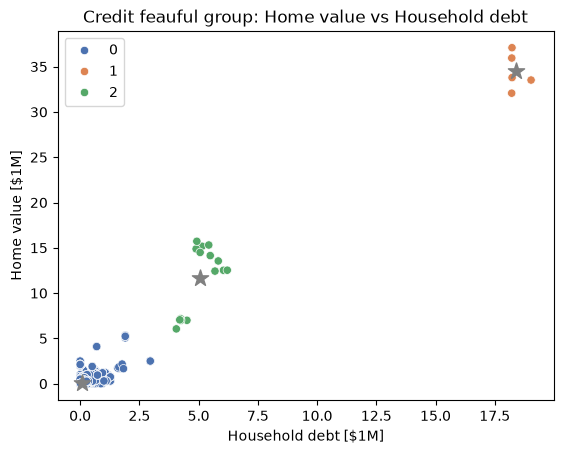

In [34]:
sns.scatterplot(x=df_fear["DEBT"] / 1e6, y=df_fear["HOUSES"] / 1e6, hue=labels, palette="deep")
plt.scatter(x=centroids[:,1]/ 1e6, y=centroids[:,0]/ 1e6, color="grey", marker="*", s=150)
plt.xlabel("Household debt [$1M]")
plt.ylabel("Home value [$1M]")
plt.title("Credit feauful group: Home value vs Household debt");

In [35]:
inertia = model.inertia_
inertia

939554010797047.1

In [36]:
ss = silhouette_score(X, model.labels_)
ss

0.9768842462944348

In [37]:
# Best number of clusters 
n_clusters = range(2,13)
inertia_scores = []
ss_scores = []
for cluster in n_clusters:
    model = KMeans(n_clusters=cluster, random_state=42)
    model.fit(X)
    inertia_scores.append(model.inertia_)
    ss_scores.append(silhouette_score(X, model.labels_))


Text(0.5, 1.0, 'KMeans model: Inertia vs n_clusters')

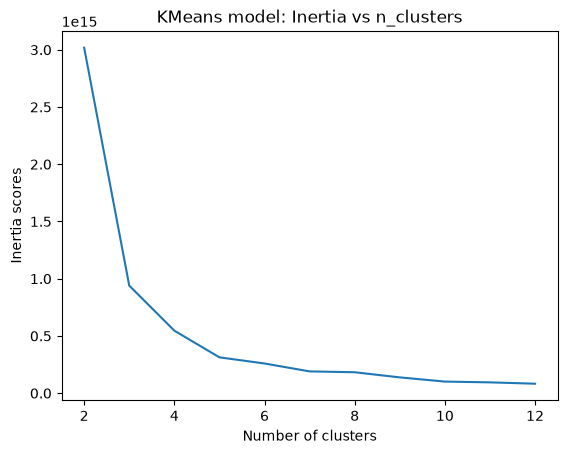

In [38]:
# Inertia vs n_clusters
plt.plot(n_clusters, inertia_scores)
plt.xlabel("Number of clusters")
plt.ylabel("Inertia scores")
plt.title("KMeans model: Inertia vs n_clusters")

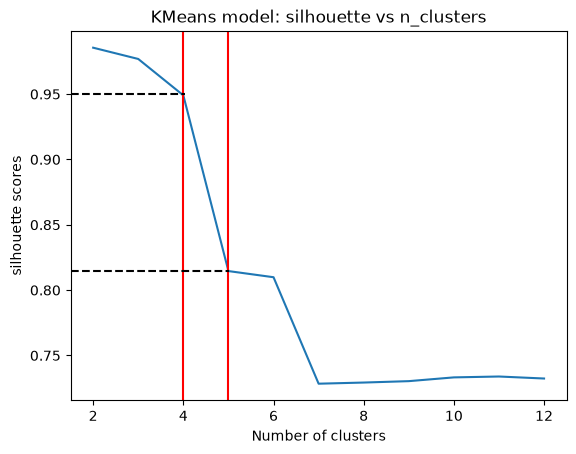

In [39]:
# Inertia vs silhouette score
plt.plot(n_clusters, ss_scores)
plt.xlabel("Number of clusters")
plt.ylabel("silhouette scores")
plt.axvline(x=4, color="Red")
plt.axvline(x=5, color="Red")
plt.axhline(y=0.95, color="black", linestyle="--", xmin=0, xmax=0.23)
plt.axhline(y=0.815, color="black", linestyle="--", xmin=0, xmax=0.32)
plt.title("KMeans model: silhouette vs n_clusters");
plt.savefig("../reports/figures/sillhouette_scores.png", dpi=150)

In [40]:
# plt.hlines(y=0.95, xmin=min(n_clusters), xmax=4, color="black", linestyle="--")
# plt.hlines(y=0.815, xmin=min(n_clusters), xmax=5, color="black", linestyle="--")

### Selecting the Optimal Number of Clusters

The **Elbow Method** (based on the inertia score) suggests that both **4** and **5** clusters are potential candidates, as they represent the critical elbow points where the reduction in inertia begins to diminish.

To determine the optimal number of clusters, we further evaluated the models using the **Silhouette Score**, which measures cluster cohesion and separation. The silhouette score for **4 clusters** is noticeably higher than that for **5 clusters**, indicating that the data is better partitioned into four well-defined groups.

Therefore, we selected **4 clusters** as the optimal configuration for the final **K-Means clustering model**.

In [41]:
final_model = KMeans(n_clusters=4, random_state=42)
final_model.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)","[

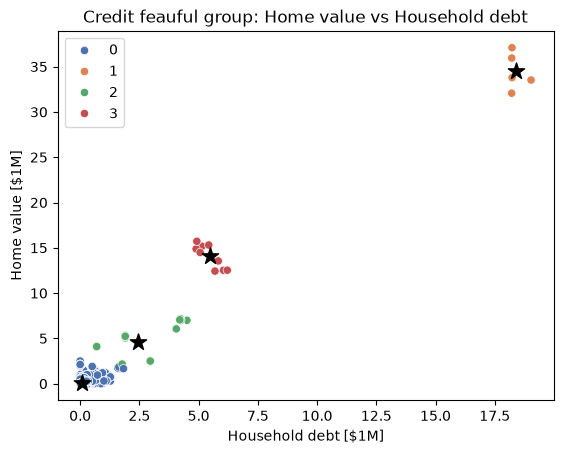

In [42]:
sns.scatterplot(x=df_fear["DEBT"] / 1e6, y=df_fear["HOUSES"] / 1e6, hue=final_model.labels_ , palette="deep")
plt.scatter(x=final_model.cluster_centers_[:,1]/1e6, y=final_model.cluster_centers_[:,0]/1e6, color="black", marker="*", s=150)
plt.xlabel("Household debt [$1M]")
plt.ylabel("Home value [$1M]")
plt.title("Credit feauful group: Home value vs Household debt");
plt.savefig("../reports/figures/final_model_clusters.png", dpi=150)


### Alternative Approach for Computing Cluster Centers

An alternative method for obtaining the cluster centers is to compute them directly from the cluster assignments stored in `model.labels_`. This can be achieved by grouping the observations according to their assigned cluster labels and calculating the mean of each group.

For the K-Means algorithm, this approach produces the same cluster centroids as those stored in `model.cluster_centers_` (up to minor floating-point differences), since each centroid is defined as the mean of all data points assigned to its cluster. This method is also useful for clustering algorithms that do not provide cluster centers explicitly, allowing representative centroids to be computed from the final cluster assignments.

In [43]:
xgb = X.groupby(final_model.labels_).mean()
xgb

,HOUSES,DEBT
0,1.031872e+05,8.488629e+04
1,3.448400e+07,1.838410e+07
2,4.551429e+06,2.420929e+06
3,1.407400e+07,5.472800e+06


In [44]:
pd.DataFrame(final_model.cluster_centers_, columns=["HOUSES", "DEBT"])

,HOUSES,DEBT
0,1.031872e+05,8.488629e+04
1,3.448400e+07,1.838410e+07
2,4.551429e+06,2.420929e+06
3,1.407400e+07,5.472800e+06


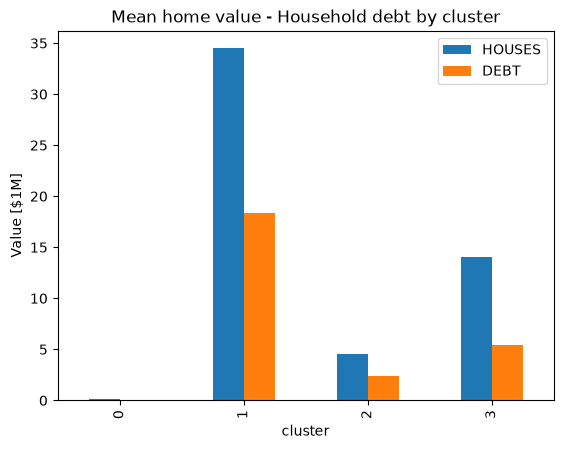

In [45]:
(xgb/1e6).plot(kind="bar")
plt.xlabel("cluster")
plt.ylabel("Value [$1M]")
plt.title("Mean home value - Household debt by cluster");

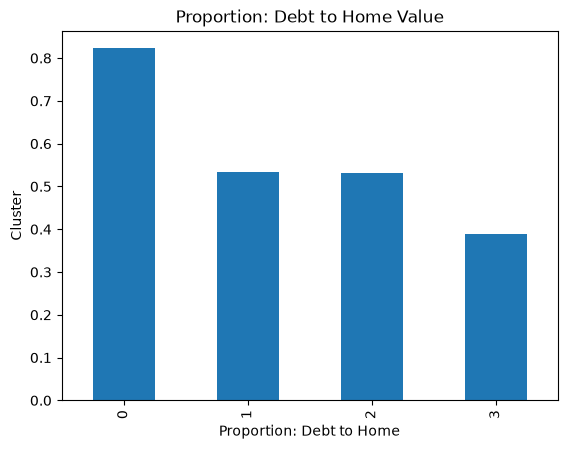

In [46]:
(xgb["DEBT"]/xgb["HOUSES"]).plot(kind="bar", xlabel="Proportion: Debt to Home", ylabel="Cluster", title="Proportion: Debt to Home Value");

### Debt-to-Home-Value Ratio

The **debt-to-home-value ratio** indicates the proportion of a household's home value that is financed through debt. From the graph, **Cluster 0** exhibits the highest ratio among all clusters. This suggests that mortgage debt accounts for the largest share of total debt for households in this group. In other words, a significant portion of their liabilities is tied to home mortgages, indicating that housing-related borrowing is their primary source of debt.

### Home Equity

In contrast, **Cluster 3** has the lowest debt-to-home-value ratio, at approximately **0.40**. This indicates that only about 40% of the value of their homes is financed through debt, while the remaining 60% represents home equity. 

# Clustering using multiple features

In [47]:
from scipy.stats.mstats import trimmed_var
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import plotly_express as px

In [51]:
df_fear["NETWORTH"].describe()

count    4.623000e+03
mean     1.418464e+06
std      1.747396e+07
min     -8.928000e+05
25%     -1.645000e+02
50%      1.141000e+04
75%      8.771000e+04
max      5.120240e+08
Name: NETWORTH, dtype: float64

In the Survey of Consumer Finances (SCF), net worth is defined as:

Net Worth = Total Assets − Total Liabilities (Debts)

It measures a household's overall wealth by subtracting everything it owes from everything it owns.

In [56]:
df_fear["NETWORTH"].describe()

count    4.623000e+03
mean     1.418464e+06
std      1.747396e+07
min     -8.928000e+05
25%     -1.645000e+02
50%      1.141000e+04
75%      8.771000e+04
max      5.120240e+08
Name: NETWORTH, dtype: float64

In [ ]:
# subset the data by NETWORTH < 2000_000 to avoid extreme values (Outliers)
df_fear = df_fear[df_fear["NETWORTH"]<2e6]
df_fear.shape

(4418, 352)

### Feature Selection for K-Means Clustering

When applying the **K-Means clustering algorithm**, selecting features with higher variance can improve the ability of the model to distinguish between different groups. Features with greater variability contain more information and provide better separation between observations, allowing the algorithm to identify meaningful differences among clusters.

By focusing on high-variance features, we increase the potential to create clusters that represent distinct patterns or behaviors within the data. However, feature selection should also consider domain relevance, as high variance alone does not always guarantee that a feature is useful for interpretation.

In [64]:
# Calculate varience and get the 10 largest features
top_ten_var = df_fear.var().sort_values().tail(10)
top_ten_var

PLOAN1      1.140894e+10
ACTBUS      1.251892e+10
BUS         1.256643e+10
KGTOTAL     1.346475e+10
DEBT        1.848252e+10
NHNFIN      2.254163e+10
HOUSES      2.388459e+10
NETWORTH    4.847029e+10
NFIN        5.713939e+10
ASSET       8.303967e+10
dtype: float64

Using **Pandas vectorized operations**, we can efficiently calculate the variance of each feature and identify the features with the highest variability. Selecting the top features with the greatest variance helps focus the K-Means algorithm on variables that provide more separation between observations and improve the ability to identify meaningful clusters.


In [65]:
# Horizontal bar-chart of 'top_ten_var'
fig = px.bar(
    x=top_ten_var,
    y=top_ten_var.index,
    title="SCF: Top 10 high variance features "
)
fig.update_layout(xaxis_title="Variance", yaxis_title="Feature")
fig.show()

### NHNFIN: Non-Financial Assets Excluding Primary Residence

**NHNFIN** represents the total value of a household's **non-financial assets excluding the primary residence**. These assets include tangible assets that have value but are not financial investments or the household's main home.

Examples of assets included in **NHNFIN** may include:
- Vehicles
- Real estate other than the primary residence
- Business ownership interests
- Other tangible non-financial assets

This measure helps capture household wealth held in physical assets outside of the primary home, providing insight into the composition of a household's overall asset portfolio.

In [81]:
fig = px.box(
    data_frame=df_fear,
    x="NHNFIN",
    title="Disatribution of Non-home, Non-financial Assets"
)
fig.update_layout(xaxis_title="Value [$]")
fig.show()

### Handling Right-Skewed Data and Extreme Outliers

The distribution of the dataset is **highly right-skewed**, as indicated by the presence of large outliers on the right side of the distribution. Although households with extremely high net worth have already been excluded, some extreme observations remain and continue to influence the variance calculation.

These outliers can significantly inflate the variance, making it less representative of the typical variation within the dataset. A more robust approach is to calculate the **trimmed variance**, which removes a specified percentage of the most extreme values from both ends of the distribution before computing the variance.

In this analysis, we will use the `trimmed_var` function from the **SciPy library** to reduce the impact of extreme observations and obtain a more reliable measure of feature variability. This will allow us to select features based on their true variation rather than being dominated by a small number of extreme values.

In [ ]:
# How trimmed_var function works
trimmed_var?

Signature:
trimmed_var(
    a,
    limits=(0.1, 0.1),
    inclusive=(1, 1),
    relative=True,
    axis=None,
    ddof=0,
)
Docstring:
Returns the trimmed variance of the data along the given axis.


Parameters
----------
a : sequence
    Input array
limits : {None, tuple}, optional
    If `relative` is False, tuple (lower limit, upper limit) in absolute values.
    Values of the input array lower (greater) than the lower (upper) limit are
    masked.

    If `relative` is True, tuple (lower percentage, upper percentage) to cut
    on each side of the  array, with respect to the number of unmasked data.

    Noting n the number of unmasked data before trimming, the (n*limits[0])th
    smallest data and the (n*limits[1])th largest data are masked, and the
    total number of unmasked data after trimming is n*(1.-sum(limits))
    In each case, the value of one limit can be set to None to indicate an
    open interval.

    If limits is None, no trimming is performed
inclusive : {(bool, b

In [73]:
# Debt actual variance
df_fear["DEBT"].var()

np.float64(18482520920.40815)

In [74]:
# Debt trimmed variance
trimmed_var(df_fear["DEBT"])

np.float64(3089864647.655702)

In [76]:
df_fear.apply(trimmed_var, limits=(0.1, 0.1))

index           4.568521e+07
YY1             1.850508e+06
Y1              1.850507e+08
WGT             1.412290e+06
HHSEX           2.019627e-01
                    ...     
NWPCTLECAT      2.580682e+00
INCPCTLECAT     3.429553e+00
NINCPCTLECAT    3.523264e+00
INCQRTCAT       5.850373e-01
NINCQRTCAT      6.002715e-01
Length: 352, dtype: float64

In [80]:
# Top 10 trimmed_var features
top_ten_trim_var = df_fear.apply(trimmed_var, limits=(0.1,0.1)).sort_values().tail(10)
top_ten_trim_var

WAGEINC     5.550737e+08
HOMEEQ      7.338377e+08
NH_MORT     1.333125e+09
MRTHEL      1.380468e+09
PLOAN1      1.441968e+09
DEBT        3.089865e+09
NETWORTH    3.099929e+09
HOUSES      4.978660e+09
NFIN        8.456442e+09
ASSET       1.175370e+10
dtype: float64

In [82]:
fig = px.bar(
    x=top_ten_trim_var,
    y=top_ten_trim_var.index,
    title="Top ten trimmed variance features"
)
fig.update_layout(xaxis_title="Trimmed Variance", yaxis_title="Feature")
fig.show()

### Impact of Trimming on Feature Selection

After applying the **trimmed variance** calculation, we observe that the **Non-Home Non-Financial Assets (NHNFIN)** feature is no longer among the top features with the highest variance. This indicates that the previously observed high variability in this feature was largely driven by extreme outliers.

By removing the influence of extreme observations, the trimmed variance provides a more accurate representation of the typical variation within the dataset. As a result, features that consistently show high variance after trimming are more likely to capture meaningful differences between households and provide better separation for K-Means clustering.

### Selecting the Highest Variance Features

After calculating the trimmed variance for each feature, we select the **five features with the highest variance** to use for clustering. This subset allows us to focus the K-Means algorithm on the variables that contain the most meaningful variation across households.

In [ ]:
high_var_cols = top_ten_trim_var.tail(5).index.to_list()
high_var_cols

['DEBT', 'NETWORTH', 'HOUSES', 'NFIN', 'ASSET']

In [97]:
# Feature matrix with 5 features for KMeans
X = df_fear[high_var_cols]
X.head()


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
0,12200.0,-6710.0,0.0,3900.0,5490.0
1,12600.0,-4710.0,0.0,6300.0,7890.0
2,15300.0,-8115.0,0.0,5600.0,7185.0
3,14100.0,-2510.0,0.0,10000.0,11590.0
4,15400.0,-5715.0,0.0,8100.0,9685.0


### Feature Scaling for K-Means Clustering

Due to the different scales and ranges of the selected five features, it is important to apply feature scaling before training the **K-Means model**. Features with larger numerical values can dominate the distance calculations used by K-Means, causing the algorithm to give more importance to those variables regardless of their actual contribution.

By scaling the features to a comparable range, we ensure that each feature contributes proportionally to the clustering process. This improves the model's ability to identify meaningful patterns and create well-separated clusters based on the underlying characteristics of the data.

In [ ]:
X_summary = X.aggregate(["mean", "std"]).astype("int")
X_summary

,DEBT,NETWORTH,HOUSES,NFIN,ASSET
mean,72701,76387,74530,117330,149089
std,135950,220159,154546,239038,288166


In [114]:
scaler = StandardScaler()
x_scalled = scaler.fit_transform(X)

In [115]:
pd.DataFrame(x_scalled).aggregate(["mean", "std"]).astype("int")

,0,1,2,3,4
mean,0,0,0,0,0
std,1,1,1,1,1


### Selecting the Optimal Number of Clusters

After reducing the dataset to the five selected features and applying feature scaling, we can now train the **K-Means clustering algorithm** and evaluate different numbers of clusters.

To determine the optimal number of clusters, we will calculate two evaluation metrics:

- **Inertia:** Measures the total within-cluster sum of squared distances. Lower inertia indicates more compact clusters, but it typically decreases as the number of clusters increases. The elbow point helps identify where adding more clusters provides diminishing returns.
- **Silhouette Score:** Measures how well each observation fits within its assigned cluster compared to other clusters. A higher silhouette score indicates better-defined and more separated clusters.

By analyzing both inertia and silhouette scores across different values of `n_clusters`, we can select the number of clusters that provides the best balance between cluster compactness and separation.

In [118]:
n_clusters = range(2,13)
inertia_scores = []
ss_scores= []
for cluster in n_clusters:
    model = make_pipeline(
        StandardScaler(),
        KMeans(n_clusters=cluster, random_state=42)
        
    )
    model.fit(X)
    inertia_scores.append(model.named_steps["kmeans"].inertia_)
    ss_scores.append(silhouette_score(X,model.named_steps["kmeans"].labels_))


In [119]:
# Learning Curves
fig= px.line(
    x=n_clusters,
    y=inertia_scores,
    title="Kmeans- 5 features - Inertia vs n_clusters"
)
fig.update_layout(xaxis_title="Number of Clusters", yaxis_title="Inertia")
fig.show()

In [120]:
fig= px.line(
    x=n_clusters,
    y=ss_scores,
    title="Kmeans- 5 features - Silhouette Score vs n_clusters"
)
fig.update_layout(xaxis_title="Number of Clusters", yaxis_title="Silhouette Score")
fig.show()

### Selecting the Optimal Number of Clusters

Based on the **inertia** and **silhouette score** results, we will select **4 clusters** as the optimal number for the K-Means model.

According to the **elbow method**, both 4 and 5 clusters appear to be reasonable choices, as the reduction in inertia begins to slow down around this range. However, when considering the **silhouette score**, the 4-cluster solution achieves a significantly higher value compared to 5 clusters.

A higher silhouette score indicates better-defined and more separated clusters. Therefore, the 4-cluster model provides a better balance between cluster compactness and separation, making it the preferred choice for this analysis.

In [122]:
# Final model
final_model = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=4, random_state=42)
)
final_model.fit(X)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kmeans', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['DEBT','NETWORTH','HOUSES','NFIN','ASSET']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Communicating results

In [ ]:

labels

array([1, 1, 1, ..., 0, 0, 0], shape=(4418,), dtype=int32)

In [125]:
clusters = final_model.named_steps["kmeans"].cluster_centers_
clusters

array([[ 0.97406948,  0.70432094,  1.21269778,  0.97875917,  0.9976479 ],
       [-0.32405511, -0.29355841, -0.38752177, -0.3726938 , -0.37716158],
       [ 4.3893    ,  2.29660637,  4.61904235,  4.1881857 ,  3.82538962],
       [ 1.42623273,  6.15872453,  1.71221564,  4.93046776,  5.37814868]])

In [142]:
xgb = pd.DataFrame(x_scalled, columns=high_var_cols).groupby(labels).mean()
xgb

,DEBT,NETWORTH,HOUSES,NFIN,ASSET
0,0.974069,0.704321,1.212698,0.978759,0.997648
1,-0.324055,-0.293558,-0.387522,-0.372694,-0.377162
2,4.389300,2.296606,4.619042,4.188186,3.825390
3,1.426233,6.158725,1.712216,4.930468,5.378149


In [143]:
# Plotting the clusters (cluster centers)
fig = px.bar(
    xgb,
    barmode="group",
    title ="Mean Household Finances by Cluster"
)
fig.update_layout(xaxis_title="Cluster", yaxis_title="Value [$]")
fig.show()

### Interpreting Cluster Profiles

The cluster profiles reveal meaningful differences in how households allocate their wealth. For **Cluster 0**, the average value of **home assets** is nearly equal to the average value of **total assets**, suggesting that most of the wealth held by households in this group is concentrated in their primary residence. In other words, their homes represent the dominant component of their asset portfolio.

In contrast, **Cluster 3** exhibits a different pattern. The average home value accounts for only about half of the group's total assets, indicating that these households own substantial assets beyond their primary residence. These may include financial investments, retirement accounts, businesses, or other non-housing assets.

This highlights the importance of **storytelling** when interpreting clustering results. While the K-Means algorithm groups observations based on numerical similarity, the real value of clustering lies in translating those patterns into meaningful insights about the underlying characteristics and behaviors of each group.

# PCA

In [145]:
pca = PCA(n_components=2, random_state=42)
x_t = pca.fit_transform(X)
X_pca = pd.DataFrame(x_t, columns=["PC1", "PC2"])
X_pca.head()

,PC1,PC2
0,-221525.424530,22052.273003
1,-217775.100722,22851.358068
2,-219519.642175,19023.646333
3,-212195.720367,22957.107039
4,-215540.507551,20259.749306


In [152]:
# Create scatter plot of `PC2` vs `PC1` - Visualize our groups
fig = px.scatter(
    data_frame=X_pca,
    x="PC1",
    y="PC2",
    color=labels.astype("str"),
    title="PCA Representation of Clusters"
)
fig.update_layout(xaxis_title="PC1", yaxis_title="PC2")
fig.show()
